# Búsqueda de la señal de 794 nm (Rama B): toma con la fibra realineada

Es la misma medida que `FWM.ipynb`: el 822 nm (bombeo, 46 mW) está fijo en el máximo de dos fotones, la semilla de 852 nm se barre a través de la D2 con una onda triangular de 40 mHz, la celda de Cs está a 60 °C y el láser de 794 nm está apagado. La exposición del QuTau es de 100 ms. Se repitió después de **realinear la lente que colima la luz hacia la fibra multimodo, con mayor acople a la fibra**. Respecto a la toma anterior (`data/`):

| | Toma anterior (`data/`) | Esta toma (`new-data/`) |
|---|---|---|
| Potencia del 852 | 500 µW | 1 mW |
| Monocromador | 793.0 a 795.0 nm | 792.0 a 797.0 nm, en pasos de 0.2 nm |
| Filtros ND | 2, 4, 8, 10 | 2 |
| 822 solo y 852 solo | sí | no |

* **Canal A** (PMT lateral): fluorescencia azul de la cascada $8S\to 7P\to 6S$. Con el 822 fijo muestra los valles sub-Doppler F′=3, 4 y 5 de la clase $v_z\approx 0$, es decir, marca dónde el 852 es resonante con los átomos que excita el 822.
* **Canal B** (filtros ND → fibra → monocromador → SPCM): la luz que sale de la celda hacia adelante.

**Qué se espera.** La señal paramétrica $\propto|\chi^{(3)}_B|^2$ es resonante en $\delta_2 = \Delta_2 - \Delta_3 = 0$. Con el 822 en $\Delta_2 = 0$, eso ocurre en las frecuencias de los valles del canal A. Una señal de FWM se vería en el canal B como **picos** en esas frecuencias, y solo con el monocromador cerca de la línea 8S F=4 → 6P3/2 (794.606 nm).

Esta toma no incluye el 822 solo ni el 852 solo. Por eso el máximo de la fluorescencia de dos fotones, el piso del detector y la plantilla de transmisión del 852 se toman de `data/` (secciones 1 y 3), después de comprobar que la forma del canal B no cambió.

**Columnas:** col 0 no se usa, col 1 λ del láser barrido (nm), col 2 Singles A (cuentas/s), col 3 Singles B (cuentas/s), col 4 ν del láser barrido (THz).
**Nombre:** `852-<desintonía del 822>-<P 852>-<P 822>-<λ monocromador>-<T>-<ND>.txt`.

In [1]:
import sys
sys.path.append('../..')  # carpeta raíz del repositorio, donde está constants.py
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d

from constants import c, kB, cte

C_LIGHT = c*1e-3  # nm*THz
NEW = 'new-data'  # esta toma
OLD = 'data'      # toma anterior: referencias y comparación
T_EXP = 0.1  # tiempo de exposición del QuTau [s]
F_BAR = 40   # frecuencia de la onda triangular del láser barrido [mHz]

# Estructura hiperfina (THz), la misma de Rama_B/Fluorescencia. 6S y 6P3/2: Steck; 8S1/2: A = 219.125 MHz (Fendel et al. 2007)
HF_6S_F4 = 4.021776399375e-3
HF_6P = {5: 263.81e-6, 4: 12.815e-6, 3: -188.4885e-6}
HF_8S_F4 = 7/4 * 219.125e-6
S_D2 = {5: 11/18, 4: 7/24, 3: 7/72}  # intensidades relativas de 6S F=4 -> 6P3/2 F' (Steck)

NU_852 = cte['nu_ba[Hz]']*1e-12 - HF_6S_F4 + HF_6P[5]          # 6S F=4 -> 6P3/2 F'=5
NU_822 = (cte['nu_ca[Hz]']*1e-12 - HF_6S_F4 + HF_8S_F4) / 2    # mitad de 6S F=4 -> 8S F=4
NU_794 = {F: (cte['nu_ca[Hz]'] - cte['nu_ba[Hz]'])*1e-12 + HF_8S_F4 - HF_6P[F] for F in (5, 4, 3)}  # 8S F=4 -> 6P3/2 F'
DET_FP = {F: (HF_6P[F] - HF_6P[5])*1e6 for F in (5, 4, 3)}      # F' respecto a F'=5 (MHz)
LAM_794 = C_LIGHT/NU_794[4]

def doppler_fwhm(nu, T_C):
    # FWHM Doppler (MHz) de un haz a frecuencia nu (THz), átomos a T_C (°C)
    return nu*1e6*np.sqrt(8*kB*(T_C + 273.15)*np.log(2) / (cte['m_Cs[kg]']*c**2))

print(f'ν(F=4→F′=5)   = {NU_852:.6f} THz  (λ = {C_LIGHT/NU_852:.6f} nm)')
print(f'ν_TP/2        = {NU_822:.6f} THz  (λ = {C_LIGHT/NU_822:.6f} nm)')
print('λ 8S F=4 → 6P3/2 F′ (nm):', {F: round(C_LIGHT/v, 5) for F, v in NU_794.items()})
print('F′ respecto a F′=5 (MHz):', {F: round(v, 1) for F, v in DET_FP.items()})
print(f'FWHM Doppler del 852 a 60 °C: {doppler_fwhm(NU_852, 60):.1f} MHz')

C1, C2, C3, INK, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#8a8984'
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

ν(F=4→F′=5)   = 351.721961 THz  (λ = 852.356383 nm)
ν_TP/2        = 364.503080 THz  (λ = 822.468929 nm)
λ 8S F=4 → 6P3/2 F′ (nm): {5: 794.60645, 4: 794.60592, 3: 794.60549}
F′ respecto a F′=5 (MHz): {5: 0.0, 4: -251.0, 3: -452.3}
FWHM Doppler del 852 a 60 °C: 398.8 MHz


## Lectura

Igual que en `FWM.ipynb`. Se descartan las filas sin lectura válida del láser barrido (λ a más de 1 nm del láser del nombre) y las que tienen 0 cuentas en algún canal (las primeras lecturas de cada archivo). Los campos del nombre se reconocen por su sufijo (`MHz`, `mW`/`muW`, `nm`, `C`, `ND`). El barrido triangular se corta en rampas en los extremos de λ suavizada.

In [2]:
def parse_name(path):
    # <láser barrido>-[<desint. fijo>]-<P barrido>-[<P fijo>]-<λ monocromador>-<T>-<ND>.txt
    f = os.path.basename(path)[:-4].split('-')
    meta = dict(laser=int(f[0]), det_fijo=None, P_fijo=None)
    P = []
    for s in f[1:]:
        if s.endswith('MHz'):
            meta['det_fijo'] = float(s[:-3])
        elif s.endswith('muW'):
            P.append(float(s[:-3])*1e-3)
        elif s.endswith('mW'):
            P.append(float(s[:-2]))
        elif s.endswith('ND'):
            meta['ND'] = int(s[:-2])
        elif s.endswith('C'):
            meta['T'] = float(s[:-1])
        else:
            meta['lam_mono'] = float(s.removesuffix('nm'))  # con o sin sufijo 'nm'
    meta['P'] = P[0]
    if len(P) > 1:
        meta['P_fijo'] = P[1]
    return meta

def load(path):
    meta = parse_name(path)
    d = np.loadtxt(path)
    k = (np.abs(d[:, 1] - meta['laser']) < 1) & (d[:, 2] > 0) & (d[:, 3] > 0)
    ref = NU_822 if meta['laser'] == 822 else NU_852
    t = np.linspace(0, 1, len(d))[k]  # orden de adquisición, para la deriva lenta
    return meta, dict(lam=d[k, 1], det=(d[k, 4] - ref)*1e6, A=d[k, 2], B=d[k, 3], t=t, n_desc=int((~k).sum()))

def ramps(lam, w=9, dist=40):
    # Índices de cada rampa del barrido triangular, cortando en los extremos de lambda
    s = uniform_filter1d(lam, w)
    t = np.sort(np.r_[find_peaks(s, distance=dist)[0], find_peaks(-s, distance=dist)[0]])
    edges = np.r_[0, t, len(lam)]
    return [np.arange(a, b) for a, b in zip(edges[:-1], edges[1:]) if b - a > 5]

def binned(x, y, bin_w):
    # Media y desviación estándar de y en bins de ancho bin_w (MHz)
    xb = np.floor(x/bin_w)*bin_w + bin_w/2
    ux = np.unique(xb)
    return ux, np.array([y[xb == u].mean() for u in ux]), np.array([y[xb == u].std() for u in ux])

def mark_Fp(ax):
    # Líneas verticales en las transiciones F=4 → F'=3, 4, 5 (átomos con v_z = 0)
    for F, x0 in DET_FP.items():
        ax.axvline(x0, ls='--', lw=0.8, color=GRID)
        ax.annotate(f"F′={F}", (x0, 1), xycoords=('data', 'axes fraction'), xytext=(2, -10),
                    textcoords='offset points', fontsize=8, color=GRID)

FMONO = sorted(glob.glob(os.path.join(NEW, '*.txt')), key=lambda f: parse_name(f)['lam_mono'])

# Toma anterior (500 µW): 822 solo, 852 solo y 822 + 852 con ND 2
old = sorted(glob.glob(os.path.join(OLD, '*.txt')))
F822 = [f for f in old if parse_name(f)['laser'] == 822][0]
FSOLO = [f for f in old if parse_name(f)['laser'] == 852 and parse_name(f)['P_fijo'] is None]
FOLD = sorted([f for f in old if parse_name(f)['P_fijo'] is not None and parse_name(f)['ND'] == 2],
              key=lambda f: parse_name(f)['lam_mono'])

print(f"{'archivo':42s} {'P852':>5s} {'fijo':>13s} {'mono':>6s} {'ND':>3s} {'filas':>6s} {'desc.':>5s} {'rampas':>6s} {'rango (MHz)':>15s}")
for f in FMONO:
    meta, d = load(f)
    fijo = f"{meta['P_fijo']:g} mW, {meta['det_fijo']:g} MHz"
    print(f"{os.path.basename(f):42s} {meta['P']:5g} {fijo:>13s} {meta['lam_mono']:6.1f} {meta['ND']:3d} "
          f"{len(d['A']) + d['n_desc']:6d} {d['n_desc']:5d} {len(ramps(d['lam'])):6d} {d['det'].min():7.0f}…{d['det'].max():.0f}")

archivo                                     P852          fijo   mono  ND  filas desc. rampas     rango (MHz)
852-0MHz-1mW-46mW-792nm-60C-2ND.txt            1  46 mW, 0 MHz  792.0   2    550     2      4   -1057…597
852-0MHz-1mW-46mW-792.2nm-60C-2ND.txt          1  46 mW, 0 MHz  792.2   2    550     1      4   -1047…604
852-0MHz-1mW-46mW-792.4nm-60C-2ND.txt          1  46 mW, 0 MHz  792.4   2    544     1      4   -1054…589
852-0MHz-1mW-46mW-792.6nm-60C-2ND.txt          1  46 mW, 0 MHz  792.6   2    749     1      5   -1073…599
852-0MHz-1mW-46mW-792.8nm-60C-2ND.txt          1  46 mW, 0 MHz  792.8   2    559     2      4   -1077…571
852-0MHz-1mW-46mW-793nm-60C-2ND.txt            1  46 mW, 0 MHz  793.0   2    564     1      4   -1088…566
852-0MHz-1mW-46mW-793.2nm-60C-2ND.txt          1  46 mW, 0 MHz  793.2   2    389     1      3   -1089…557
852-0MHz-1mW-46mW-793.4nm-60C-2ND.txt          1  46 mW, 0 MHz  793.4   2    740     2      5   -1101…568
852-0MHz-1mW-46mW-793.6nm-60C-2ND.txt     

## 1. Referencias de la toma anterior

Esta toma no tiene barridos de referencia, así que se usan dos valores de `data/`:

* **Máximo de la fluorescencia de dos fotones** (canal A, 822 barrido solo): gaussiana más línea base sobre el promedio de las rampas, igual que en `FWM.ipynb`. Sirve para saber si el 822 estaba en el máximo, comparándolo con la línea base del canal A con el 822 fijo. El PMT lateral no pasa por la fibra, así que la realineación no debería cambiarlo.
* **Piso del detector** (canal B, 852 solo con ND 8 y 10): cuentas oscuras más luz ambiente del SPCM, que no dependen del acople a la fibra.

In [3]:
def gauss(x, c0, x0, s, a):
    return c0 + a*np.exp(-(x - x0)**2 / (2*s**2))

def fit_gauss(x, y):
    k = np.argmax(uniform_filter1d(y, 5))
    popt, pcov = curve_fit(gauss, x, y, p0=[np.percentile(y, 5), x[k], 150, y[k]], maxfev=20000)
    return popt, np.sqrt(np.diag(pcov))

meta822, d = load(F822)
x, m, s = binned(d['det'], d['A'], 10.0)
popt, perr = fit_gauss(x, m)
A_MAX_822 = popt[0] + popt[3]
FLOOR = np.mean([load(f)[1]['B'].mean() for f in FSOLO if parse_name(f)['ND'] >= 8])

print(f"822 solo ({os.path.basename(F822)}): centro {popt[1]:.1f} ± {perr[1]:.1f} MHz, FWHM {2.3548*abs(popt[2]):.0f} MHz, "
      f"máximo {A_MAX_822:.0f} cuentas/s")
print(f'Piso del detector (852 solo, ND 8 y 10): {FLOOR:.0f} cuentas/s')

822 solo (822-46mW-60C-10ND-794.txt): centro 51.3 ± 2.8 MHz, FWHM 411 MHz, máximo 5842 cuentas/s
Piso del detector (852 solo, ND 8 y 10): 231 cuentas/s


## 2. Canal A con el 852 barrido y el 822 fijo

Igual que en `FWM.ipynb`: línea base lineal menos tres lorentzianas (valles F′=3, 4 y 5 de la clase $v_z\approx 0$), sobre el promedio de las rampas en bins de 10 MHz. La línea base se compara con el máximo del 822 solo. Si el 822 está a $\delta_1$ del máximo de dos fotones, selecciona otra clase de velocidad y los valles se corren en $\delta_1\,\nu_{852}/\nu_{822}$.

Las posiciones y los anchos de estos valles definen, para cada barrido, dónde debería aparecer una señal de FWM en el canal B (sección 4).

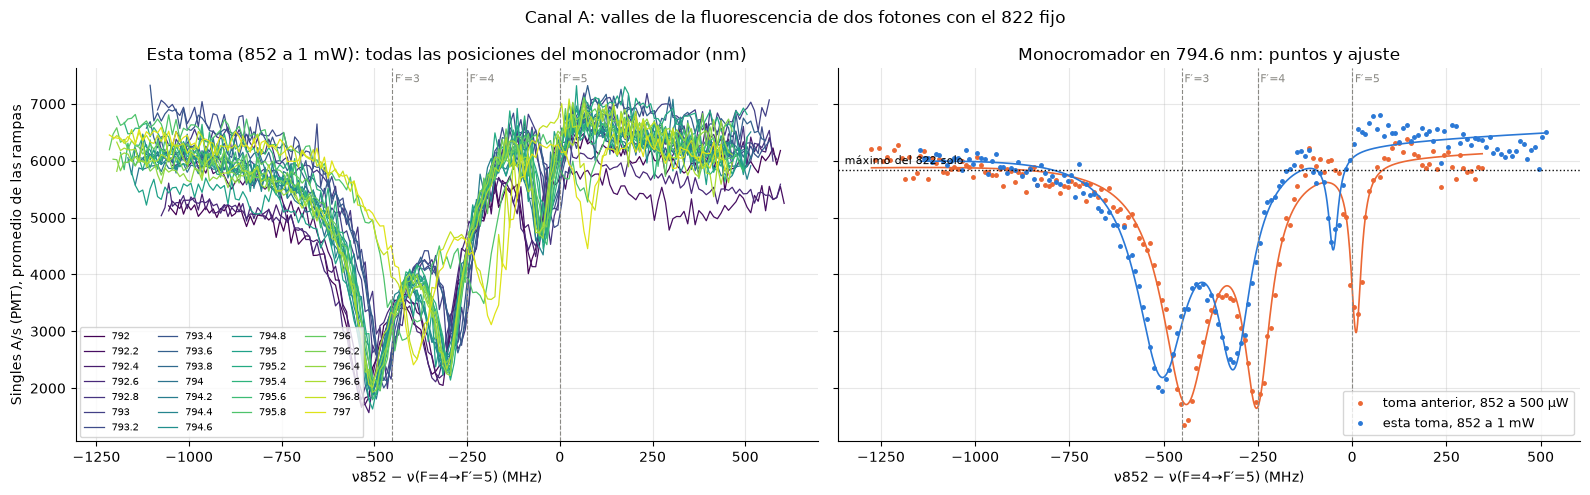

archivo                                     base b/máx | F′=3: x0 ± σ FWHM prof. | F′=4: x0 ± σ FWHM prof. | F′=5: x0 ± σ FWHM prof. | corr. δ1 impl.
852-0MHz-1mW-46mW-792nm-60C-2ND.txt         5915  1.01 |   -530 ± 3    156  3384 |   -331 ± 2    122  3088 |    -79 ± 2     27  1724 |   -79      -82
852-0MHz-1mW-46mW-792.2nm-60C-2ND.txt       5575  0.95 |   -524 ± 2    163  3697 |   -326 ± 2     95  3148 |    -71 ± 2     26  1521 |   -73      -75
852-0MHz-1mW-46mW-792.4nm-60C-2ND.txt       6108  1.05 |   -522 ± 2    153  3563 |   -326 ± 2    105  3268 |    -68 ± 2     37  1577 |   -71      -73
852-0MHz-1mW-46mW-792.6nm-60C-2ND.txt       5687  0.97 |   -535 ± 3    165  3340 |   -337 ± 2     98  3107 |    -79 ± 3     29  1165 |   -83      -86
852-0MHz-1mW-46mW-792.8nm-60C-2ND.txt       6566  1.12 |   -464 ± 2    175  3787 |   -274 ± 2     87  3269 |    -24 ± 2     28  1895 |   -19      -20
852-0MHz-1mW-46mW-793nm-60C-2ND.txt         6772  1.16 |   -476 ± 3    180  3861 |   -281 ± 2    100

In [4]:
def lorentz(x, x0, g, a):
    return a*(g/2)**2 / ((x - x0)**2 + (g/2)**2)

def dips(x, c0, c1, *p):
    return c0 + c1*x*1e-3 - sum(lorentz(x, *p[i:i + 3]) for i in range(0, len(p), 3))

def fit_dips(x, y):
    # Valle más profundo (F'=3) + F'=4 y F'=5 a las separaciones tabuladas. Devuelve {F: (x0, FWHM, prof.)} y errores
    c0 = np.percentile(y, 90)
    k = np.argmin(uniform_filter1d(y, 3))
    p0 = [c0, 0]
    for F, g0 in ((3, 150), (4, 90), (5, 40)):
        p0 += [x[k] + DET_FP[F] - DET_FP[3], g0, 0.8*(c0 - y[k])]
    popt, pcov = curve_fit(dips, x, y, p0=p0, maxfev=20000)
    perr = np.sqrt(np.diag(pcov))
    js = sorted(range(2, 11, 3), key=lambda j: popt[j])  # ordena por frecuencia: F'=3, 4, 5
    val = {F: (popt[j], abs(popt[j + 1]), popt[j + 2]) for F, j in zip((3, 4, 5), js)}
    err = {F: perr[j:j + 3] for F, j in zip((3, 4, 5), js)}
    return popt, val, err

resA = {}
for f in FMONO + FOLD:
    meta, d = load(f)
    x, m, s = binned(d['det'], d['A'], 10.0)
    popt, val, err = fit_dips(x, m)
    resA[f] = dict(meta, x=x, m=m, popt=popt, base=popt[0], val=val, err=err)
    resA[f]['shift'] = np.mean([val[F][0] - DET_FP[F] for F in (3, 4, 5)])

lm = np.array([parse_name(f)['lam_mono'] for f in FMONO])
cols = plt.cm.viridis(np.linspace(0, 0.95, len(FMONO)))

fig, axs = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for f, col in zip(FMONO, cols):
    R = resA[f]
    axs[0].plot(R['x'], R['m'], '-', lw=0.9, color=col, label=f"{R['lam_mono']:g}")
axs[0].set_title('Esta toma (852 a 1 mW): todas las posiciones del monocromador (nm)')
axs[0].legend(fontsize=7, ncol=4, loc='lower left')
f_new = [f for f in FMONO if parse_name(f)['lam_mono'] == 794.6][0]
f_old = [f for f in FOLD if parse_name(f)['lam_mono'] == 794.6][0]
for f, col, lab in ((f_old, C2, 'toma anterior, 852 a 500 µW'), (f_new, C1, 'esta toma, 852 a 1 mW')):
    R = resA[f]
    axs[1].plot(R['x'], R['m'], 'o', ms=2.5, color=col, label=lab)
    xx = np.linspace(R['x'].min(), R['x'].max(), 2000)
    axs[1].plot(xx, dips(xx, *R['popt']), '-', color=col, lw=1.2)
axs[1].axhline(A_MAX_822, ls=':', color=INK, lw=1)
axs[1].annotate('máximo del 822 solo', (axs[1].get_xlim()[0], A_MAX_822), xytext=(5, 4), textcoords='offset points', fontsize=8)
axs[1].set_title('Monocromador en 794.6 nm: puntos y ajuste')
axs[1].legend(fontsize=9, loc='lower right')
for ax in axs:
    mark_Fp(ax)
    ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
axs[0].set_ylabel('Singles A/s (PMT), promedio de las rampas')
fig.suptitle('Canal A: valles de la fluorescencia de dos fotones con el 822 fijo', fontsize=12)
fig.tight_layout()
plt.show()

print(f"{'archivo':42s} {'base':>5s} {'b/máx':>5s} |" + ''.join(f" {f'F′={F}: x0 ± σ':>12s} {'FWHM':>4s} {'prof.':>5s} |" for F in (3, 4, 5))
      + f" {'corr.':>5s} {'δ1 impl.':>8s}")
for f in FMONO + [None] + FOLD:
    if f is None:
        print('toma anterior (852 a 500 µW, ND 2):')
        continue
    R = resA[f]
    cs = ''.join(f" {R['val'][F][0]:6.0f} ± {R['err'][F][0]:<3.0f} {R['val'][F][1]:4.0f} {R['val'][F][2]:5.0f} |" for F in (3, 4, 5))
    print(f"{os.path.basename(f):42s} {R['base']:5.0f} {R['base']/A_MAX_822:5.2f} |{cs} {R['shift']:5.0f} {R['shift']*NU_822/NU_852:8.0f}")
print(f"\nTabulado (MHz): F′=3 en {DET_FP[3]:.1f}, F′=4 en {DET_FP[4]:.1f}, F′=5 en 0. x0 y FWHM en MHz, profundidad en cuentas/s. "
      f"'corr.' = corrimiento medio de los valles respecto a lo tabulado; 'δ1 impl.' = desintonía del 822 que lo explicaría.")
for lab, F in (('esta toma', FMONO), ('toma anterior', FOLD)):
    print(f"{lab:14s}: base/máx {np.mean([resA[f]['base'] for f in F])/A_MAX_822:.2f}, corr. {np.mean([resA[f]['shift'] for f in F]):.0f} ± "
          f"{np.std([resA[f]['shift'] for f in F]):.0f} MHz, FWHM " + ', '.join(f"F′={Fp}: {np.mean([resA[f]['val'][Fp][1] for f in F]):.0f}" for Fp in (3, 4, 5)) + ' MHz')

## 3. ¿Qué ve el canal B?

En la toma anterior, con ND 2, B era casi todo **luz de la semilla de 852 nm transmitida por la celda** que llegaba al SPCM a pesar del monocromador: un pozo de absorción Doppler de la D2 que bajaba hasta ≈ 6 % de transmisión, más ≈ 1150–1650 cuentas/s de luz del 822. Aquí se compara esa forma con la de esta toma.

Cada promedio (bins de 20 MHz) se normaliza a 1 lejos de resonancia ($\nu_{852} < -900$ MHz) y a 0 en el fondo del pozo ($|\nu_{852}| < 150$ MHz). Si todas las curvas coinciden, la forma de B la fija la transmisión del 852 y no depende del monocromador ni del cambio de alineamiento.

La plantilla de transmisión del 852, $T_{852}$, sale del 852 solo con ND 2 de la toma anterior, igual que en `FWM.ipynb`: $T = 1$ lejos de resonancia y $T = 0$ en el piso del detector.

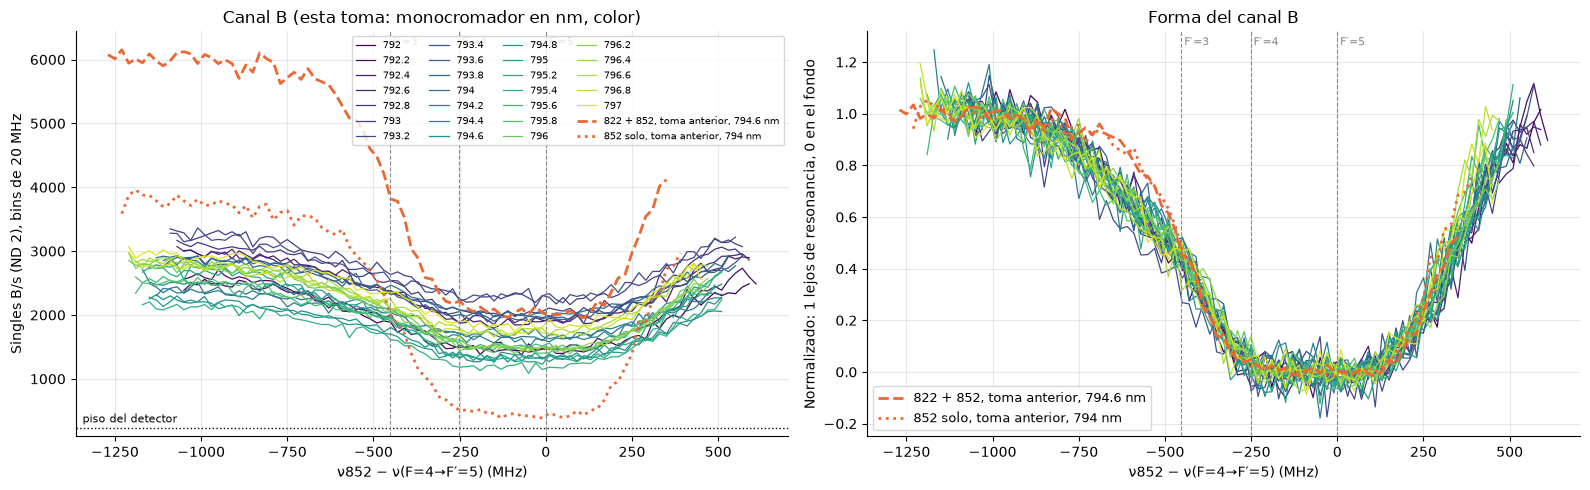

Forma normalizada, esta toma frente al 852 solo anterior: diferencia rms 0.098 (rango 0.078–0.148) en bins de 20 MHz
Transmisión mínima del 852 en la plantilla: 0.058; plantilla definida en -1230…390 MHz


In [5]:
def norm_profile(f, bin_w=20.0):
    meta, d = load(f)
    x, m, _ = binned(d['det'], d['B'], bin_w)
    off, bot = m[x < -900].mean(), m[np.abs(x) < 150].mean()
    return meta, x, m, (m - bot)/(off - bot)

# Plantilla de transmisión del 852, del 852 solo con ND 2 de la toma anterior
F_T = [f for f in FSOLO if parse_name(f)['ND'] == 2][0]
meta_T, XT, mT, NT = norm_profile(F_T)
mT = uniform_filter1d(mT, 3)
TT = (mT - FLOOR)/(mT[XT < -900].mean() - FLOOR)

def T852(x):
    return np.interp(x, XT, TT)

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for f, col in zip(FMONO, cols):
    meta, x, m, n = norm_profile(f)
    axs[0].plot(x, m, '-', lw=0.9, color=col, label=f"{meta['lam_mono']:g}")
    axs[1].plot(x, n, '-', lw=0.9, color=col)
for f, ls, lab in ((f_old, '--', '822 + 852, toma anterior, 794.6 nm'), (F_T, ':', '852 solo, toma anterior, 794 nm')):
    meta, x, m, n = norm_profile(f)
    axs[0].plot(x, m, ls, lw=2, color=C2, label=lab)
    axs[1].plot(x, n, ls, lw=2, color=C2, label=lab)
axs[0].axhline(FLOOR, ls=':', color=INK, lw=1)
axs[0].annotate('piso del detector', (axs[0].get_xlim()[0], FLOOR), xytext=(5, 4), textcoords='offset points', fontsize=8)
axs[0].set_ylabel('Singles B/s (ND 2), bins de 20 MHz')
axs[0].set_title('Canal B (esta toma: monocromador en nm, color)')
axs[0].legend(fontsize=7, ncol=4)
axs[1].set_ylabel('Normalizado: 1 lejos de resonancia, 0 en el fondo')
axs[1].set_title('Forma del canal B')
axs[1].legend(fontsize=9)
for ax in axs:
    mark_Fp(ax)
    ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
fig.tight_layout()
plt.show()

# Diferencia entre la forma de cada toma nueva y la del 852 solo de la toma anterior, donde se solapan
dn = []
for f in FMONO:
    meta, x, m, n = norm_profile(f)
    k = (x > XT.min()) & (x < XT.max())
    dn.append(np.sqrt(np.mean((n[k] - np.interp(x[k], XT, NT))**2)))
print(f'Forma normalizada, esta toma frente al 852 solo anterior: diferencia rms {np.mean(dn):.3f} '
      f'(rango {np.min(dn):.3f}–{np.max(dn):.3f}) en bins de 20 MHz')
print(f'Transmisión mínima del 852 en la plantilla: {TT[np.abs(XT) < 150].mean():.3f}; '
      f'plantilla definida en {XT.min():.0f}…{XT.max():.0f} MHz')

### ¿Se movió el 852 o el 822?

Los valles de A se corren entre tomas mucho más que en la toma anterior (sección 2). Si fuera deriva del medidor de onda del 852, el pozo de absorción de B, que lo forman los átomos de todas las velocidades, se correría lo mismo. Si lo que cambia es la frecuencia del 822, cambia la clase de velocidad que excita y solo se mueven los valles. El centro del pozo se mide sin modelo: es el punto medio entre los dos cruces de la mitad de su profundidad, en el promedio suavizado (bins de 20 MHz).

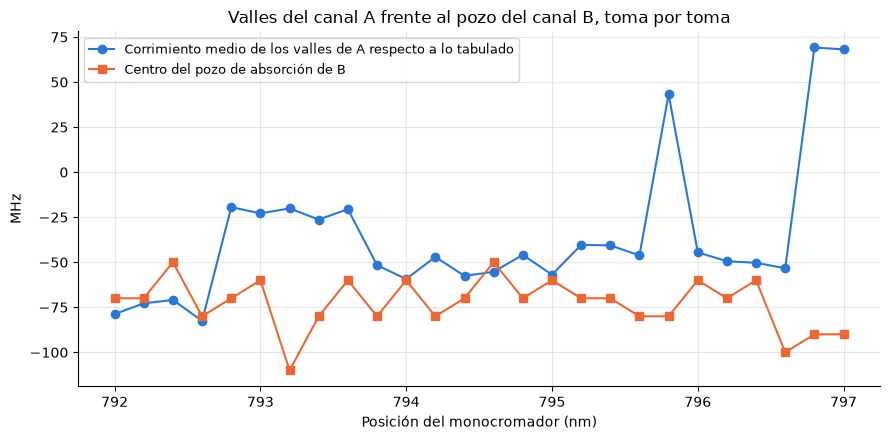

Centro del pozo de B: -73 ± 14 MHz (rango -110…-50)
Corrimiento de los valles de A: -36 ± 39 MHz (rango -83…69)


In [6]:
def well_center(f):
    _, d = load(f)
    x, m, _ = binned(d['det'], d['B'], 20.0)
    top, bot = m[x < -950].mean(), m[np.abs(x) < 150].mean()
    k = (x > -800) & (x < 400)
    xb = x[k][uniform_filter1d(m[k], 5) < (top + bot)/2]
    return (xb.min() + xb.max())/2

wc = np.array([well_center(f) for f in FMONO])
sh = np.array([resA[f]['shift'] for f in FMONO])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(lm, sh, 'o-', color=C1, label='Corrimiento medio de los valles de A respecto a lo tabulado')
ax.plot(lm, wc, 's-', color=C2, label='Centro del pozo de absorción de B')
ax.set_xlabel('Posición del monocromador (nm)')
ax.set_ylabel('MHz')
ax.set_title('Valles del canal A frente al pozo del canal B, toma por toma')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f'Centro del pozo de B: {wc.mean():.0f} ± {wc.std():.0f} MHz (rango {wc.min():.0f}…{wc.max():.0f})')
print(f'Corrimiento de los valles de A: {sh.mean():.0f} ± {sh.std():.0f} MHz (rango {sh.min():.0f}…{sh.max():.0f})')

## 4. Prueba: ¿hay en el canal B una componente ligada a los valles del canal A?

Como en `FWM.ipynb`, con la forma de la transmisión tomada de la plantilla del 852 solo, se ajusta

$$B = b_0 + b_t\,(t - \tfrac12) + s\,T_{852}\!\left(x_c + \frac{x - x_c - \delta x}{w}\right) + \sum_{F'=3,4,5} b_{F'}\,L_{F'}(x),$$

donde $x = \nu_{852} - \nu(F{=}4\to F'{=}5)$ y:

* $b_0$ es lo que queda cuando el 852 está absorbido: el piso del detector más la luz que el 822 manda al SPCM. Se acota a $b_0 \ge$ piso.
* $s$ es la luz del 852 que llega al SPCM fuera de resonancia.
* $\delta x$ corre la plantilla (deriva del medidor de onda entre tomas) y $w$ la estira alrededor del centro del pozo, $x_c = -100$ MHz.
* $b_t$ es una deriva lenta en el tiempo de adquisición.
* $L_{F'}(x)$ es una lorentziana de altura 1 con el centro y el ancho del valle F′ del canal A del mismo barrido (sección 2).

Una señal de FWM daría $b_{F'} > 0$: picos en B donde el 852 es resonante con la clase que excita el 822.

La plantilla solo llega hasta +390 MHz, así que el ajuste usa $x < 370$ MHz. El tramo que se descarta está en el flanco derecho del pozo, lejos de los valles de A.

**Incertidumbre.** Como en `FWM.ipynb`: se ajusta cada rampa completa por separado (con $\delta x$ y $w$ fijos, el resto es lineal) y se toma el error de cada $b_{F'}$ como el mayor entre el del ajuste y la dispersión entre rampas dividida entre $\sqrt{n}$.

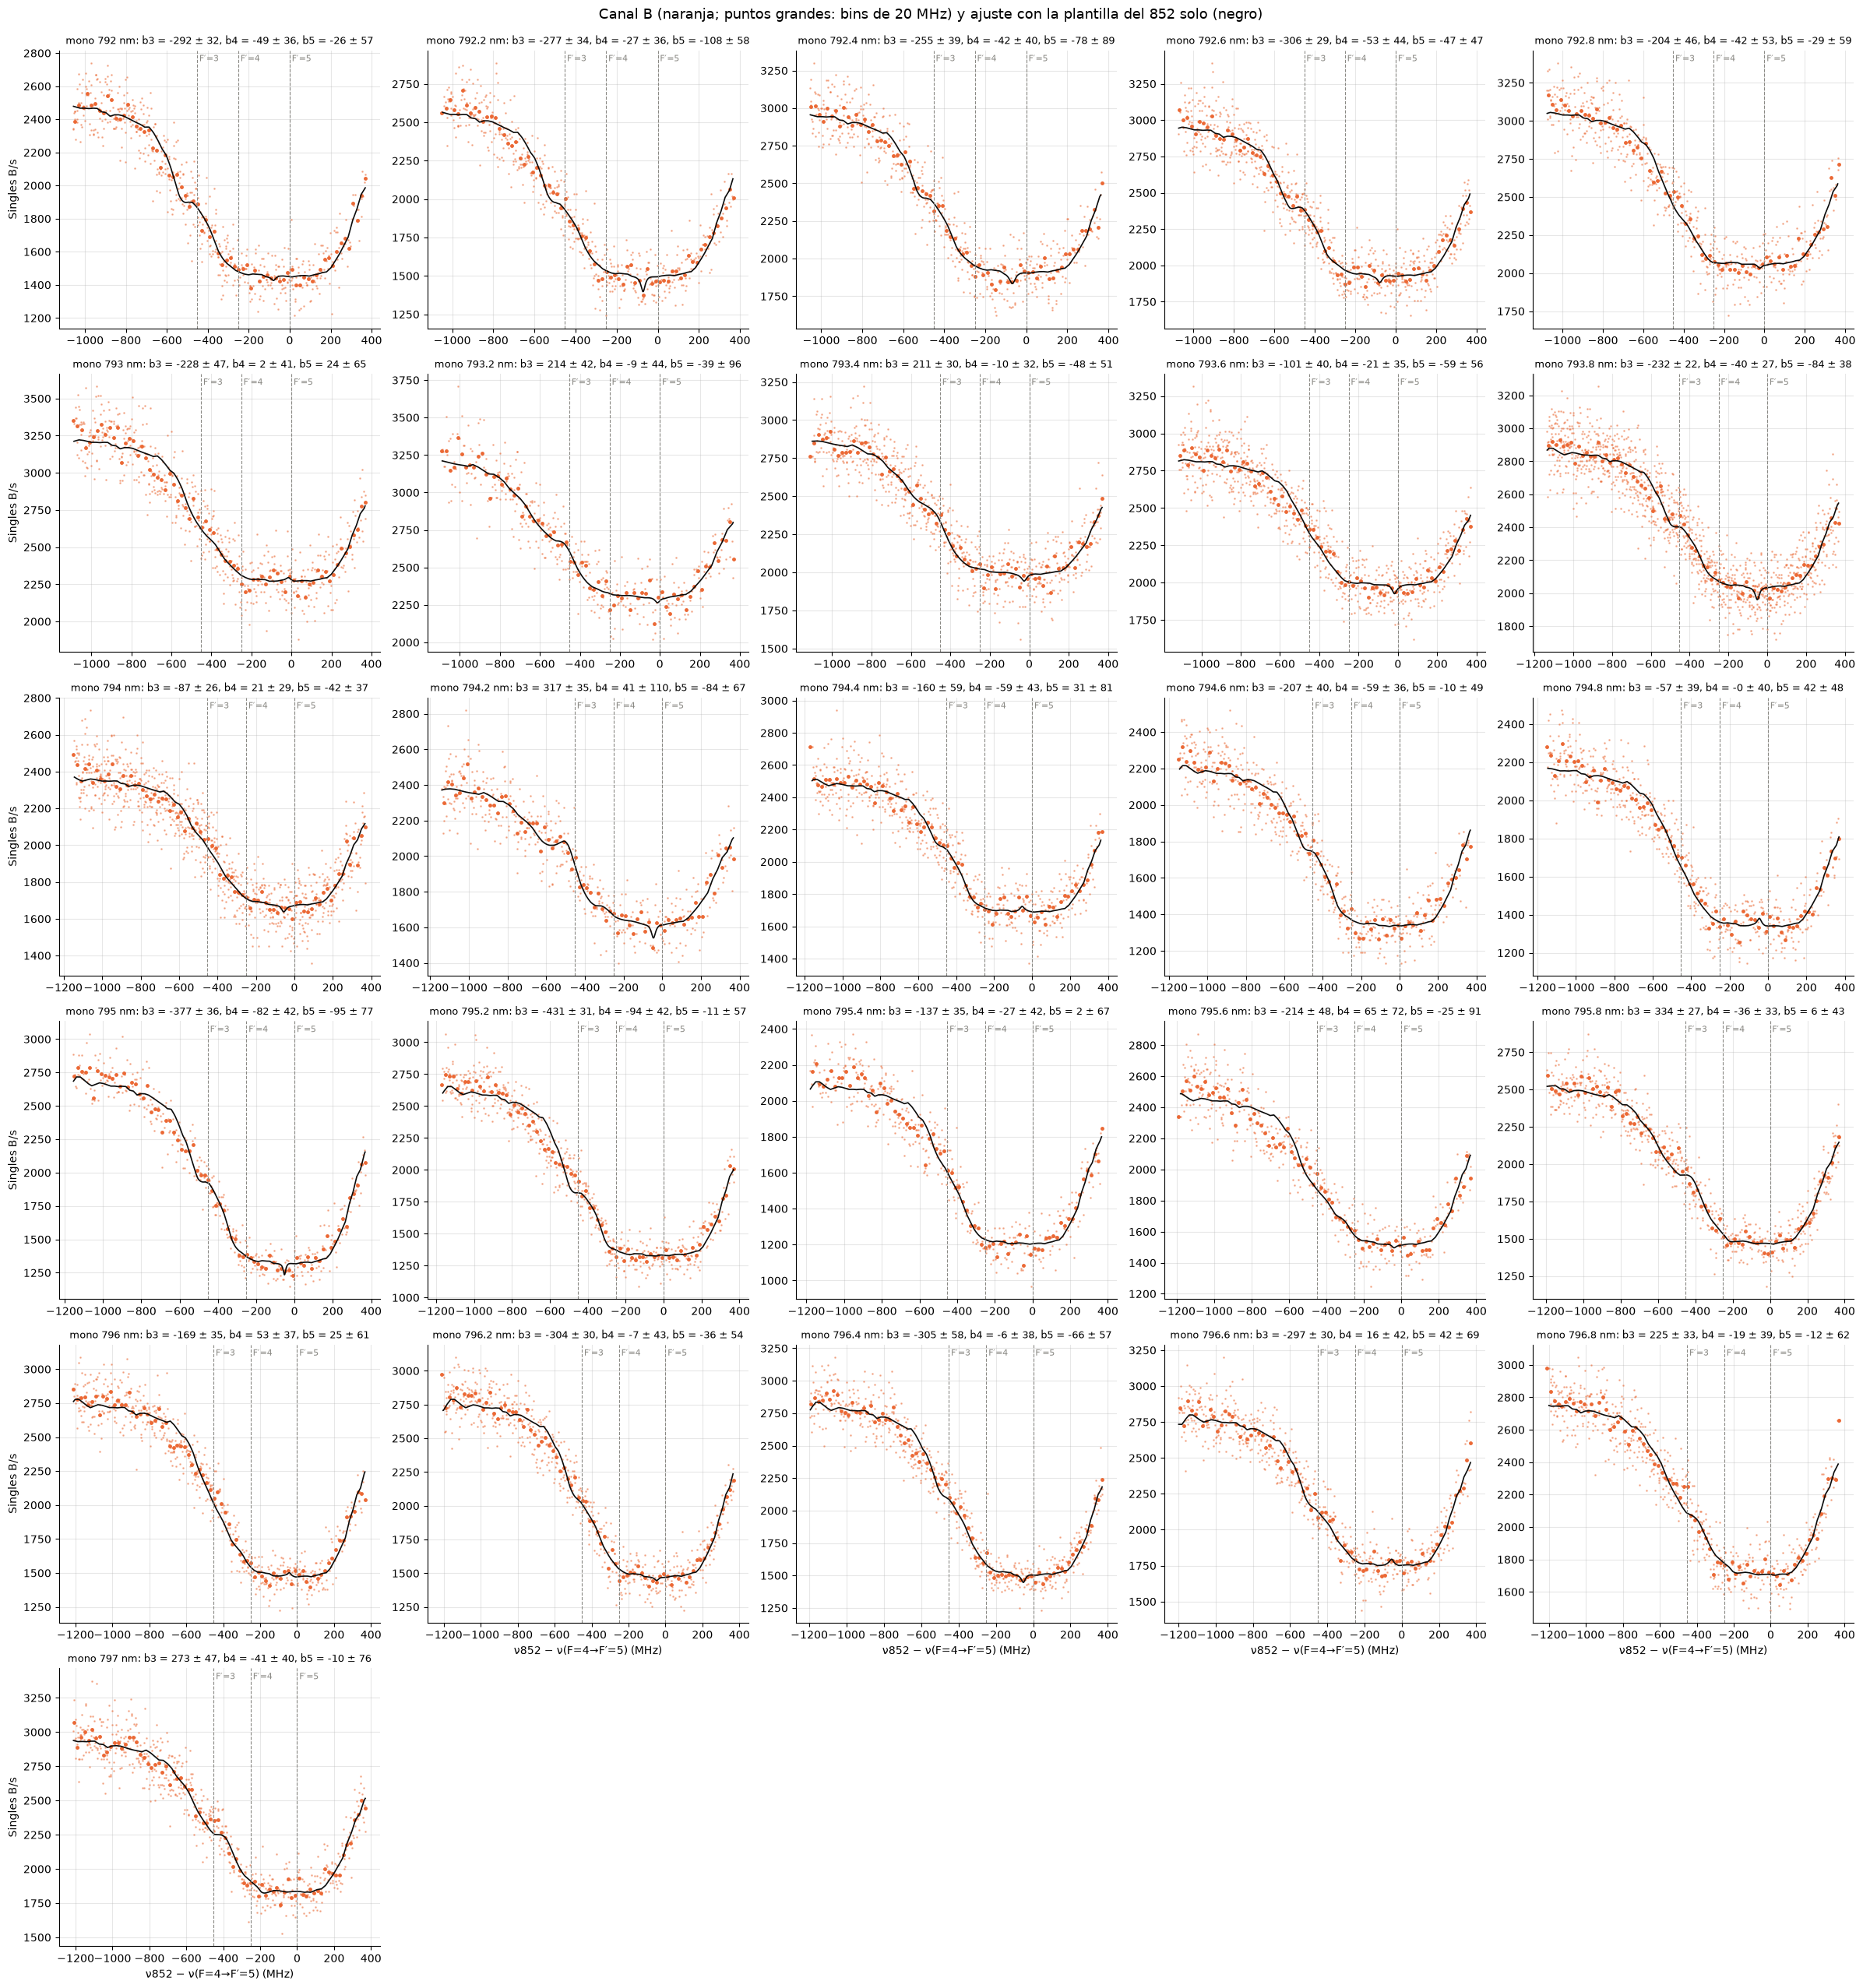

In [7]:
XC = -100.0  # centro del pozo de absorción del 852 (MHz)
FPS = (3, 4, 5)
SIG_D = doppler_fwhm(NU_852, 60)/2.3548

def T852w(x, dx, w):
    return T852(XC + (x - XC - dx)/w)

def T852dop(x, k, od, dx, w):
    # Absorción Doppler de F=4 -> F'=3, 4, 5 con las intensidades tabuladas; k: pendiente de la potencia del 852 (1/GHz)
    D = sum(S_D2[F]*np.exp(-(x - DET_FP[F] - dx)**2 / (2*(w*SIG_D)**2)) for F in FPS)/S_D2[5]
    return (1 + k*x*1e-3)*np.exp(-od*D)

# Fondo de B: forma de la transmisión, sus parámetros no lineales (valor inicial y cotas) y el tramo de x que se ajusta
BG = {'plantilla': dict(shape=T852w, p0=[0, 1], lo=[-300, 0.5], hi=[300, 2], xmax=XT.max() - 20),
      'Doppler': dict(shape=T852dop, p0=[0, 1.5, 50, 1.3], lo=[-1, 0, -300, 0.5], hi=[1, 20, 300, 4], xmax=np.inf)}

def peaks(R, x):
    # Lorentzianas de altura 1 en los valles F'=3, 4, 5 del canal A del mismo barrido
    return np.array([lorentz(x, R['val'][F][0], R['val'][F][1], 1) for F in FPS])

def model_B(x, t, L, shape, b0, bt, s, b3, b4, b5, *q):
    return b0 + bt*(t - 0.5) + s*shape(x, *q) + b3*L[0] + b4*L[1] + b5*L[2]

def fit_B(f, bg='plantilla'):
    G = BG[bg]
    meta, d = load(f)
    k = d['det'] < G['xmax']
    x, B, t, lam = d['det'][k], d['B'][k], d['t'][k], d['lam'][k]
    L = peaks(resA[f], x)
    p0 = [max(B.min() - 300, FLOOR + 1), 0, B.max() - B.min(), 0, 0, 0] + G['p0']
    lo = [FLOOR, -np.inf, 0, -np.inf, -np.inf, -np.inf] + G['lo']
    hi = [np.inf]*6 + G['hi']
    popt, pcov = curve_fit(lambda X, *p: model_B(x, t, L, G['shape'], *p), x, B, p0=p0, bounds=(lo, hi), max_nfev=20000)
    perr = np.sqrt(np.diag(pcov))
    q = popt[6:]
    resid = B - model_B(x, t, L, G['shape'], *popt)

    # Rampa por rampa (con la forma fija): mínimos cuadrados lineales en b0, s, b3, b4, b5
    per = []
    for sg in ramps(lam):
        if len(sg) < 100:
            continue
        M = np.c_[np.ones(len(sg)), G['shape'](x[sg], *q), L[:, sg].T]
        per.append(np.linalg.lstsq(M, B[sg], rcond=None)[0])
    per = np.array(per)
    e_r = per.std(axis=0, ddof=1)/np.sqrt(len(per)) if len(per) > 1 else np.zeros(per.shape[1])
    b = dict(zip(FPS, popt[3:6]))
    e = {F: max(perr[3 + i], e_r[2 + i]) for i, F in enumerate(FPS)}
    return dict(meta, name=os.path.basename(f), x=x, B=B, t=t, L=L, shape=G['shape'], popt=popt, perr=perr,
                b0=popt[0], s=popt[2], q=q, b=b, e=e, z={F: b[F]/e[F] for F in FPS}, n_r=len(per),
                lim=max((max(b[F], 0) + 2*e[F]) for F in FPS),
                sB=resid.std(), sP=np.sqrt(np.mean(B)/T_EXP), resid=resid)

resB = {f: fit_B(f) for f in FMONO}

fig, axs = plt.subplots(6, 5, figsize=(24, 26))
for ax, f in zip(axs.flat, FMONO):
    R = resB[f]
    ax.plot(R['x'], R['B'], '.', ms=2, color=C2, alpha=0.4)
    xb, mb, sb = binned(R['x'], R['B'], 20.0)
    ax.plot(xb, mb, 'o', ms=2.5, color=C2)
    xs = np.linspace(R['x'].min(), R['x'].max(), 1500)
    ax.plot(xs, model_B(xs, 0.5, peaks(resA[f], xs), R['shape'], *R['popt']), '-', color=INK, lw=1.2)
    mark_Fp(ax)
    ax.set_title(f"mono {R['lam_mono']:g} nm: " + ', '.join(f"b{F} = {R['b'][F]:.0f} ± {R['e'][F]:.0f}" for F in FPS),
                 fontsize=9)
for ax in axs.flat[len(FMONO):]:
    ax.set_visible(False)
for ax in axs[:, 0]:
    ax.set_ylabel('Singles B/s')
for ax in axs.flat[len(FMONO) - 5:len(FMONO)]:
    ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
fig.suptitle('Canal B (naranja; puntos grandes: bins de 20 MHz) y ajuste con la plantilla del 852 solo (negro)', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.985))
plt.show()

Residuos del ajuste **sin** los términos $b_{F'}L_{F'}$, promediados en bins de 20 MHz y desplazados verticalmente según la posición del monocromador. La curva azul es $200\sum_{F'} L_{F'}(x)$, la forma que tendría una señal de FWM de 200 cuentas/s en cada F′. La franja gris marca la posición del monocromador más cercana a 794.606 nm.

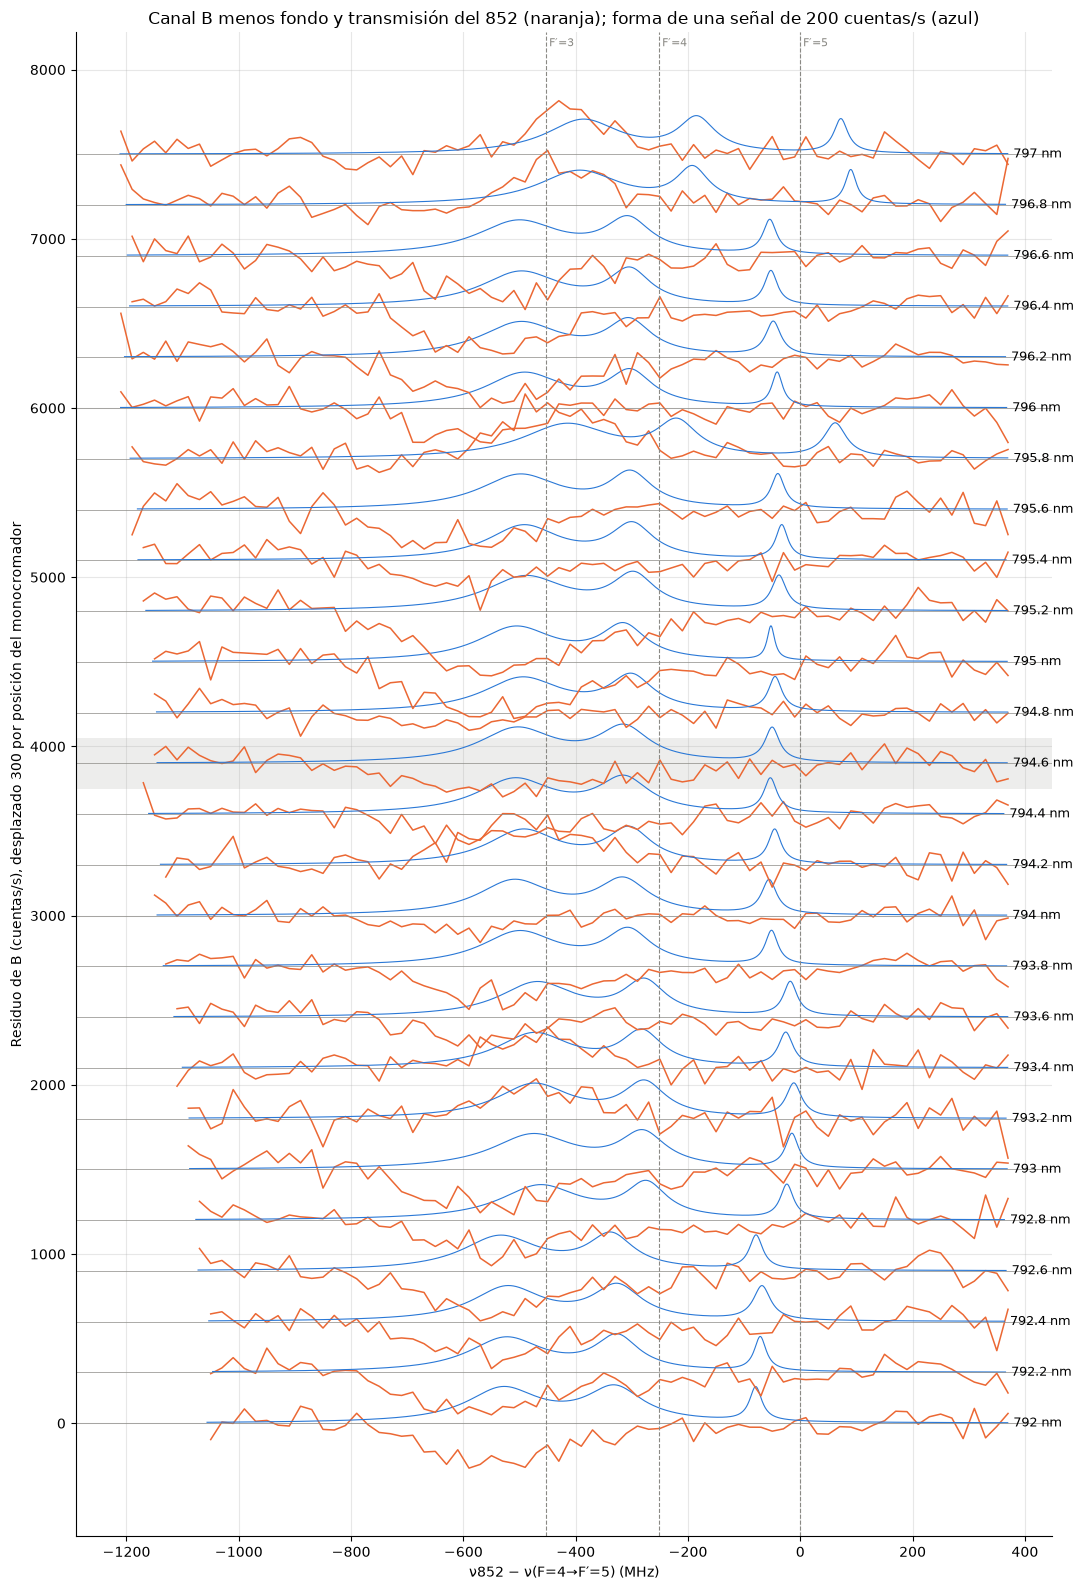

  mono    b0     s       δx           w |      b3 ± σ     z |      b4 ± σ     z |      b5 ± σ     z | lím. 2σ  σ_B Pois. ramp.
 792.0  1403  1082  37 ± 6  1.06 ± 0.02 | -292 ± 32    -9.1 |  -49 ± 36    -1.3 |  -26 ± 57    -0.5 |     114  124   138     3
 792.2  1450  1120  26 ± 5  1.03 ± 0.01 | -277 ± 34    -8.0 |  -27 ± 36    -0.7 | -108 ± 58    -1.9 |     116  127   141     3
 792.4  1859  1101  44 ± 7  1.06 ± 0.02 | -255 ± 39    -6.6 |  -42 ± 40    -1.1 |  -78 ± 89    -0.9 |     179  135   155     3
 792.6  1881  1071  38 ± 5  1.03 ± 0.01 | -306 ± 29   -10.4 |  -53 ± 44    -1.2 |  -47 ± 47    -1.0 |      94  132   154     4
 792.8  2014  1040  38 ± 7  1.03 ± 0.02 | -204 ± 46    -4.4 |  -42 ± 53    -0.8 |  -29 ± 59    -0.5 |     117  140   159     3
 793.0  2226   995  40 ± 8  1.04 ± 0.02 | -228 ± 47    -4.9 |    2 ± 41     0.1 |   24 ± 65     0.4 |     154  153   165     3
 793.2  2243  1005 -69 ± 8  1.30 ± 0.03 |  214 ± 42     5.1 |   -9 ± 44    -0.2 |  -39 ± 96    -0.4 |     299  

In [8]:
fig, ax = plt.subplots(figsize=(11, 16))
step = 300
for i, f in enumerate(FMONO):
    R = resB[f]
    if abs(R['lam_mono'] - LAM_794) < 0.1:
        ax.axhspan(i*step - step/2, i*step + step/2, color=GRID, alpha=0.15, lw=0)
    r0 = R['resid'] + sum(R['b'][F]*R['L'][j] for j, F in enumerate(FPS))
    xb, mb, _ = binned(R['x'], r0, 20.0)
    ax.plot(xb, mb + i*step, '-', lw=1.1, color=C2)
    xs = np.linspace(R['x'].min(), R['x'].max(), 1500)
    ax.plot(xs, 200*peaks(resA[f], xs).sum(axis=0) + i*step, '-', lw=0.8, color=C1)
    ax.axhline(i*step, color=GRID, lw=0.5)
    ax.annotate(f"{R['lam_mono']:g} nm", (R['x'].max(), i*step), xytext=(4, 0), textcoords='offset points',
                fontsize=9, va='center')
mark_Fp(ax)
ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
ax.set_ylabel(f'Residuo de B (cuentas/s), desplazado {step} por posición del monocromador')
ax.set_title('Canal B menos fondo y transmisión del 852 (naranja); forma de una señal de 200 cuentas/s (azul)')
fig.tight_layout()
plt.show()

print(f"{'mono':>6s} {'b0':>5s} {'s':>5s} {'δx':>8s} {'w':>11s} |"
      + ''.join(f" {f'b{F} ± σ':>11s} {'z':>5s} |" for F in FPS) + f" {'lím. 2σ':>7s} {'σ_B':>4s} {'Pois.':>5s} {'ramp.':>5s}")
for f in FMONO:
    R = resB[f]
    cs = ''.join(f" {R['b'][F]:4.0f} ± {R['e'][F]:<4.0f} {R['z'][F]:5.1f} |" for F in FPS)
    print(f"{R['lam_mono']:6.1f} {R['b0']:5.0f} {R['s']:5.0f} {R['q'][0]:3.0f} ± {R['perr'][6]:<2.0f} "
          f"{R['q'][1]:4.2f} ± {R['perr'][7]:<4.2f} |{cs} {R['lim']:7.0f} {R['sB']:4.0f} {R['sP']:5.0f} {R['n_r']:5d}")
print("\nb0, s, b_F′, σ y lím. en cuentas/s; δx en MHz; lím. 2σ = max_F′(max(b_F′, 0) + 2σ); "
      "σ_B = dispersión de los residuos; Pois. = sqrt(<B>/T_exp).")
z = np.array([[resB[f]['z'][F] for F in FPS] for f in FMONO])
for i, F in enumerate(FPS):
    print(f"b{F}: z medio {z[:, i].mean():5.2f}, desviación {z[:, i].std():.2f}, |z| máx {np.abs(z[:, i]).max():.1f}, "
          f"con |z| > 2: {(np.abs(z[:, i]) > 2).sum()} de {len(z)} (por azar ≈ {0.0455*len(z):.1f})")

### Robustez frente al modelo del fondo

Las $b_{F'}$ dependen de cómo se describa el pozo de absorción, sobre todo $b_3$: el valle F′=3 cae en el flanco izquierdo del pozo, donde la transmisión cambia más rápido. Para ver cuánto depende el resultado de la plantilla, se repite el ajuste cambiando $s\,T_{852}$ por un modelo de absorción Doppler de las tres líneas 6S F=4 → 6P3/2 F′:

$$s\,(1 + k\,x)\,\exp\!\Big[-\mathrm{OD}\sum_{F'}\frac{S_{F'}}{S_5}\,e^{-(x - x_{F'} - \delta x)^2/2(w\sigma_D)^2}\Big],$$

con $S_{F'}$ las intensidades relativas tabuladas, $\sigma_D$ el ancho Doppler a 60 °C, $k$ una pendiente de la potencia del 852 a lo largo del barrido y OD, $\delta x$ y $w$ libres. Este modelo usa todo el barrido, incluido $x > 370$ MHz. En él $b_0$, $s$ y OD están muy correlacionados, pero eso no afecta a las $b_{F'}$, que son mucho más estrechas que el pozo.

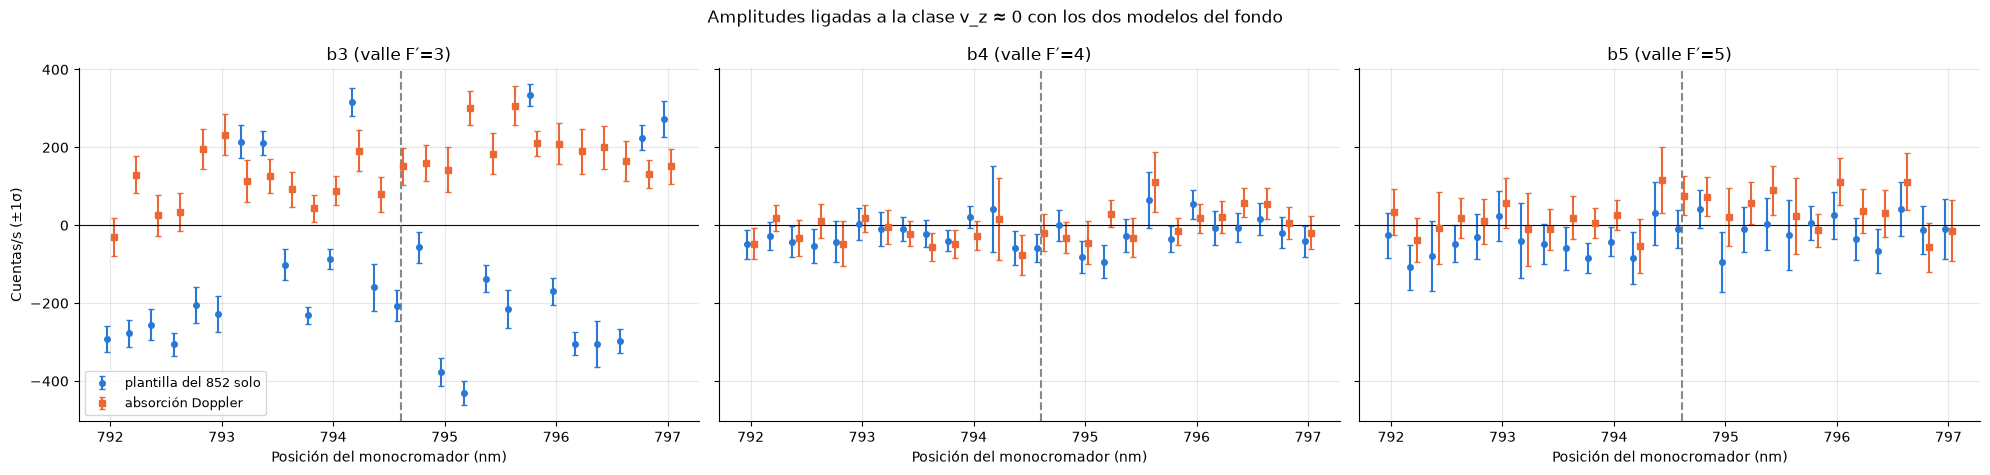

  mono |  b3 plantilla    b3 Doppler |  b4 plantilla    b4 Doppler |  b5 plantilla    b5 Doppler | σ_B pl. σ_B D.
 792.0 |  -292 ± 32      -30 ± 50    |   -49 ± 36      -48 ± 40    |   -26 ± 57       34 ± 59    |     124    120
 792.2 |  -277 ± 34      130 ± 48    |   -27 ± 36       19 ± 35    |  -108 ± 58      -37 ± 57    |     127    122
 792.4 |  -255 ± 39       25 ± 53    |   -42 ± 40      -33 ± 45    |   -78 ± 89       -7 ± 92    |     135    133
 792.6 |  -306 ± 29       33 ± 48    |   -53 ± 44       12 ± 43    |   -47 ± 47       19 ± 51    |     132    133
 792.8 |  -204 ± 46      196 ± 51    |   -42 ± 53      -47 ± 57    |   -29 ± 59       10 ± 58    |     140    134
 793.0 |  -228 ± 47      233 ± 54    |     2 ± 41       18 ± 35    |    24 ± 65       57 ± 64    |     153    146
 793.2 |   214 ± 42      115 ± 54    |    -9 ± 44       -5 ± 44    |   -39 ± 96      -10 ± 94    |     145    143
 793.4 |   211 ± 30      127 ± 43    |   -10 ± 32      -21 ± 32    |   -48 ± 51      -11

In [9]:
resD = {f: fit_B(f, 'Doppler') for f in FMONO}

fig, axs = plt.subplots(1, 3, figsize=(20, 4.8), sharey=True)
for ax, F in zip(axs, FPS):
    for res, col, mk, lab, off in ((resB, C1, 'o', 'plantilla del 852 solo', -0.03), (resD, C2, 's', 'absorción Doppler', 0.03)):
        ax.errorbar(lm + off, [res[f]['b'][F] for f in FMONO], yerr=[res[f]['e'][F] for f in FMONO],
                    fmt=mk, capsize=2, ms=4, color=col, label=lab)
    ax.axhline(0, color=INK, lw=0.8)
    ax.axvline(LAM_794, ls='--', color=GRID)
    ax.set_title(f'b{F} (valle F′={F})')
    ax.set_xlabel('Posición del monocromador (nm)')
axs[0].set_ylabel('Cuentas/s (±1σ)')
axs[0].legend(fontsize=9)
fig.suptitle('Amplitudes ligadas a la clase v_z ≈ 0 con los dos modelos del fondo', fontsize=12)
fig.tight_layout()
plt.show()

print(f"{'mono':>6s} |" + ''.join(f" {f'b{F} plantilla':>13s} {f'b{F} Doppler':>13s} |" for F in FPS) + f" {'σ_B pl.':>7s} {'σ_B D.':>6s}")
for f in FMONO:
    P, D = resB[f], resD[f]
    cs = ''.join(f" {P['b'][F]:5.0f} ± {P['e'][F]:<4.0f}  {D['b'][F]:5.0f} ± {D['e'][F]:<4.0f}  |" for F in FPS)
    print(f"{P['lam_mono']:6.1f} |{cs} {P['sB']:7.0f} {D['sB']:6.0f}")
for F in FPS:
    w_ = {n: np.array([1/r[f]['e'][F]**2 for f in FMONO]) for n, r in (('pl', resB), ('D', resD))}
    m_ = {n: np.sum(w_[n]*np.array([r[f]['b'][F] for f in FMONO]))/w_[n].sum() for n, r in (('pl', resB), ('D', resD))}
    print(f"b{F}: media ponderada de las {len(FMONO)} tomas: plantilla {m_['pl']:.0f} ± {w_['pl'].sum()**-0.5:.0f}, "
          f"Doppler {m_['D']:.0f} ± {w_['D'].sum()**-0.5:.0f} cuentas/s; |z| máx: plantilla "
          f"{max(abs(resB[f]['z'][F]) for f in FMONO):.1f}, Doppler {max(abs(resD[f]['z'][F]) for f in FMONO):.1f}")
f94 = [f for f in FMONO if abs(parse_name(f)['lam_mono'] - LAM_794) < 0.1][0]
print(f"Monocromador en {parse_name(f94)['lam_mono']:g} nm, límite 2σ de b4 y b5: plantilla {max(max(resB[f94]['b'][F], 0) + 2*resB[f94]['e'][F] for F in (4, 5)):.0f}, "
      f"Doppler {max(max(resD[f94]['b'][F], 0) + 2*resD[f94]['e'][F] for F in (4, 5)):.0f} cuentas/s")
r = np.array([resB[f]['sB']/resB[f]['sP'] for f in FMONO])
print(f"σ_B/Poisson (plantilla): {r.min():.2f}–{r.max():.2f}")

## 5. Dependencia con el monocromador

Una señal de 794 nm, sea de FWM o de fluorescencia 8S → 6P3/2, solo pasa el monocromador cuando este está cerca de 794.606 nm. La luz de 822 y de 852 que se cuela no debería depender de su posición en un intervalo de 5 nm.

Para no depender del modelo, se usan niveles medidos directamente en dos regiones de B: lejos de resonancia ($x < -950$ MHz) y el fondo del pozo ($-200 < x < 150$ MHz). La diferencia entre ambos es luz del 852 que la celda absorbe, así que es una cota inferior de la luz del 852 que llega al SPCM. El error es la dispersión entre rampas dividida entre $\sqrt{n}$. Se comparan con la toma anterior (ND 2, 852 a 500 µW).

Se grafican también $b_4$ y $b_5$ con los dos modelos del fondo. $b_3$ no se incluye porque depende del modelo (sección 4).

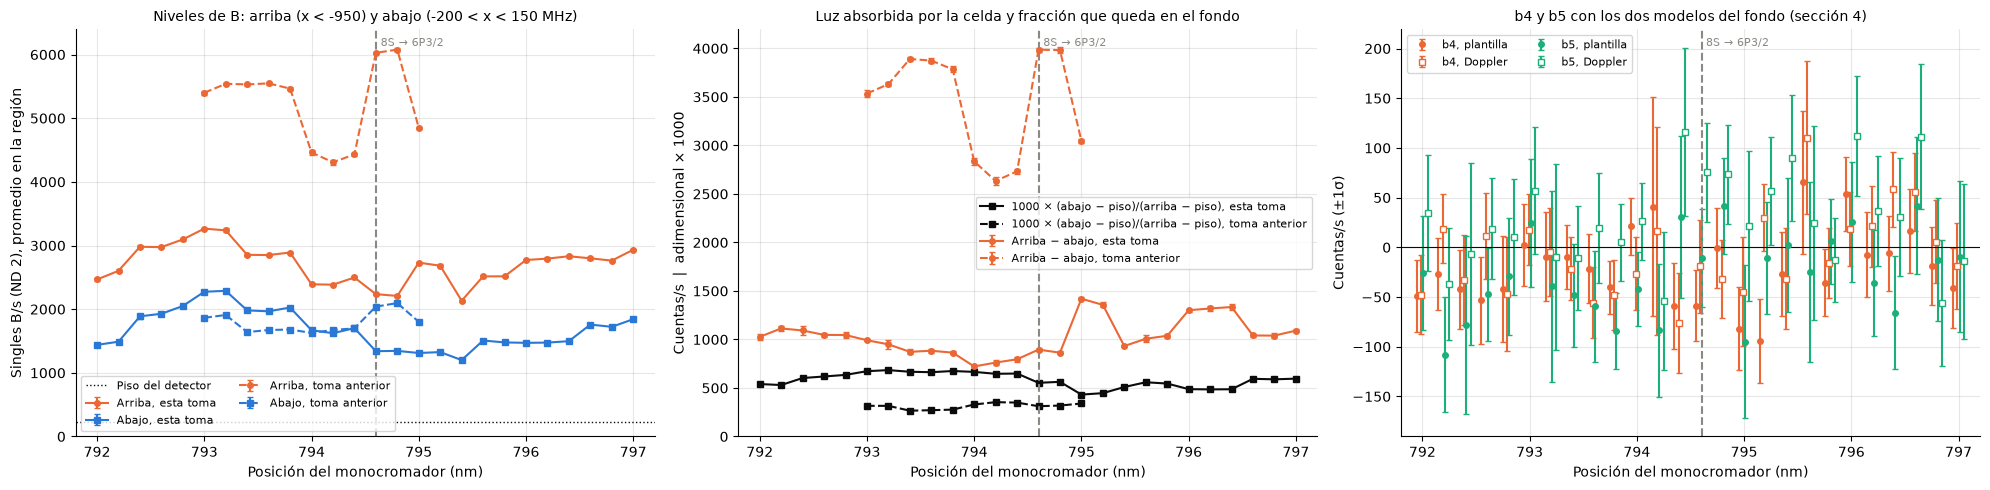

  mono   arriba ± σ    abajo ± σ arr. − ab. (ab.−piso)/(arr.−piso)
esta toma (852 a 1 mW):
 792.0   2466 ± 30     1440 ± 7          1027                  0.541
 792.2   2603 ± 24     1489 ± 12         1114                  0.530
 792.4   2980 ± 23     1888 ± 40         1093                  0.603
 792.6   2975 ± 19     1928 ± 3          1047                  0.618
 792.8   3096 ± 23     2050 ± 20         1046                  0.635
 793.0   3266 ± 12     2274 ± 5           992                  0.673
 793.2   3238 ± 33     2288 ± 34          950                  0.684
 793.4   2854 ± 11     1981 ± 24          873                  0.667
 793.6   2850 ± 14     1967 ± 15          884                  0.663
 793.8   2890 ± 11     2026 ± 11          864                  0.675
 794.0   2391 ± 11     1669 ± 7           722                  0.666
 794.2   2385 ± 11     1623 ± 26          762                  0.646
 794.4   2498 ± 23     1702 ± 10          796                  0.649
 794.6   223

In [10]:
X_ARRIBA = -950          # lejos de resonancia: x < X_ARRIBA (MHz)
X_ABAJO = (-200, 150)    # fondo del pozo de absorción (MHz)

def flat_levels(f):
    # Promedio de B en las dos regiones. Error: dispersión entre rampas / sqrt(n)
    _, d = load(f)
    x, B = d['det'], d['B']
    out = []
    for k in (x < X_ARRIBA, (x > X_ABAJO[0]) & (x < X_ABAJO[1])):
        per = [B[sg][k[sg]].mean() for sg in ramps(d['lam']) if k[sg].sum() >= 5]
        out += [B[k].mean(), np.std(per, ddof=1)/np.sqrt(len(per))]
    return out

lv = np.array([flat_levels(f) for f in FMONO])
lm_old = np.array([parse_name(f)['lam_mono'] for f in FOLD])
lv_old = np.array([flat_levels(f) for f in FOLD])

fig, axs = plt.subplots(1, 3, figsize=(20, 5))
ax = axs[0]
for L, l, ls, lab in ((lv, lm, '-', 'esta toma'), (lv_old, lm_old, '--', 'toma anterior')):
    ax.errorbar(l, L[:, 0], yerr=L[:, 1], fmt='o' + ls, capsize=2, ms=4, color=C2, label=f'Arriba, {lab}')
    ax.errorbar(l, L[:, 2], yerr=L[:, 3], fmt='s' + ls, capsize=2, ms=4, color=C1, label=f'Abajo, {lab}')
ax.axhline(FLOOR, ls=':', color=INK, lw=1, label='Piso del detector')
ax.set_ylim(0, None)
ax.set_ylabel('Singles B/s (ND 2), promedio en la región')
ax.set_title(f'Niveles de B: arriba (x < {X_ARRIBA}) y abajo ({X_ABAJO[0]} < x < {X_ABAJO[1]} MHz)', fontsize=10)
ax.legend(fontsize=8, ncol=2)
ax = axs[1]
for L, l, ls, lab in ((lv, lm, '-', 'esta toma'), (lv_old, lm_old, '--', 'toma anterior')):
    ax.errorbar(l, L[:, 0] - L[:, 2], yerr=np.hypot(L[:, 1], L[:, 3]), fmt='o' + ls, capsize=2, ms=4, color=C2,
                label=f'Arriba − abajo, {lab}')
    ax.plot(l, (L[:, 2] - FLOOR)/(L[:, 0] - FLOOR)*1e3, 's' + ls, ms=4, color=INK,
            label=f'1000 × (abajo − piso)/(arriba − piso), {lab}')
ax.set_ylim(0, None)
ax.set_ylabel('Cuentas/s  |  adimensional × 1000')
ax.set_title('Luz absorbida por la celda y fracción que queda en el fondo', fontsize=10)
axs[1].legend(fontsize=8, loc='center right')
ax = axs[2]
for j, (F, col) in enumerate(((4, C2), (5, C3))):
    for res, mk, lab, off in ((resB, 'o', 'plantilla', -0.02), (resD, 's', 'Doppler', 0.02)):
        ax.errorbar(lm + off + 0.06*(j - 0.5), [res[f]['b'][F] for f in FMONO], yerr=[res[f]['e'][F] for f in FMONO],
                    fmt=mk, mfc=col if lab == 'plantilla' else 'white', capsize=2, ms=4, color=col, label=f'b{F}, {lab}')
ax.axhline(0, color=INK, lw=0.8)
ax.set_ylabel('Cuentas/s (±1σ)')
ax.set_title('b4 y b5 con los dos modelos del fondo (sección 4)', fontsize=10)
ax.legend(fontsize=8, ncol=2)
for ax in axs:
    ax.axvline(LAM_794, ls='--', color=GRID)
    ax.annotate('8S → 6P3/2', (LAM_794, 1), xycoords=('data', 'axes fraction'), xytext=(3, -12),
                textcoords='offset points', fontsize=8, color=GRID)
    ax.set_xlim(791.8, 797.2)
    ax.set_xlabel('Posición del monocromador (nm)')
fig.tight_layout()
plt.show()

print(f"{'mono':>6s} {'arriba ± σ':>12s} {'abajo ± σ':>12s} {'arr. − ab.':>10s} {'(ab.−piso)/(arr.−piso)':>22s}")
for lab, l, L in (('esta toma (852 a 1 mW)', lm, lv), ('toma anterior (852 a 500 µW)', lm_old, lv_old)):
    print(lab + ':')
    for li, (a, ea, b, eb) in zip(l, L):
        print(f"{li:6.1f} {a:6.0f} ± {ea:<4.0f} {b:6.0f} ± {eb:<4.0f} {a - b:10.0f} {(b - FLOOR)/(a - FLOOR):22.3f}")
    print(f"  media: arriba {L[:, 0].mean():.0f} (rango {L[:, 0].min():.0f}–{L[:, 0].max():.0f}), abajo {L[:, 2].mean():.0f} "
          f"(rango {L[:, 2].min():.0f}–{L[:, 2].max():.0f}), arriba − abajo {(L[:, 0] - L[:, 2]).mean():.0f}")
print(f'x = ν852 − ν(F=4→F′=5); σ = dispersión entre rampas / sqrt(n); piso = {FLOOR:.0f} cuentas/s.')

## Conclusiones

* **Canal A:** los tres valles de la clase $v_z\approx 0$ aparecen en todas las tomas, con FWHM ≈ 168, 96 y 29 MHz (F′=3, 4 y 5), parecidos a los de la toma anterior con 500 µW (163, 86 y 33 MHz). El valle F′=5 es menos profundo (≈ 1500–1900 frente a 2700–3300 cuentas/s).
  * Los valles se corren entre tomas de −83 a +69 MHz respecto a lo tabulado (en la toma anterior, de 1 a 13 MHz). En la mayoría de las tomas el corrimiento es ≈ −50 MHz.
  * El pozo de absorción del canal B no se mueve (centro en −73 ± 14 MHz en todas las tomas). El eje del 852 es estable, así que lo que cambió fue **la frecuencia del 822**: estuvo entre ≈ −85 y +70 MHz del máximo de dos fotones, y no en el máximo como en la toma anterior.
  * La línea base es 0.95–1.16 veces el máximo del 822 solo de la toma anterior. Es una referencia de otro día, así que esta comparación es solo indicativa.
* **Canal B:** normalizado, el pozo tiene la misma forma que el del 852 solo de la toma anterior (diferencia rms 0.10). Lo que cambió es cuánta luz de cada haz llega al SPCM:
  * La luz del 852 que la celda absorbe (arriba − abajo) es de 720–1420 cuentas/s, con media 1030, frente a 2630–3990 (media 3450) antes, y con el doble de potencia. Por unidad de potencia del 852, llega ≈ 7 veces menos luz del 852 al SPCM.
  * El fondo del pozo está en 1200–2290 cuentas/s (media 1680), frente a 1630–2100 (media 1790) antes. La luz del 822 que llega al SPCM no cambió.
  * Con ND 2, B ahora está dominado por la luz del 822 más el piso: descontado el piso, el fondo del pozo es 43–68 % de la meseta, frente a 27–35 % antes.
  * Ningún nivel tiene un máximo en 794.6 nm entre 792 y 797 nm. Los niveles cambian hasta un 50 % entre tomas sin relación con la línea 8S → 6P3/2. En 794.6 y 794.8 nm la meseta está entre los valores más bajos.
* **Prueba de FWM:**
  * $b_4$ y $b_5$ son compatibles con cero en todas las tomas y con los dos modelos del fondo ($|z| \le 2.2$). Promediadas sobre las 26 tomas, quedan dentro de ±30 cuentas/s, con un signo que depende del modelo.
  * $b_3$ **depende del modelo del fondo**: −117 ± 7 cuentas/s en promedio con la plantilla, frente a +144 ± 9 con la absorción Doppler. Con la plantilla, el ajuste tiene dos soluciones ($\delta x \approx +40$ MHz y $w \approx 1$, que da $b_3 < 0$; o $\delta x \approx -35$ a $-80$ MHz y $w \approx 1.15$–1.3, que da $b_3 > 0$). El valle F′=3 cae en el flanco del pozo, así que $b_3$ mide la forma del flanco y no una señal. En ningún modelo tiene estructura alrededor de 794.6 nm.
  * Con el monocromador en 794.6 nm, cualquier señal con la forma de los valles F′=4 o F′=5 es menor que ≈ 175 cuentas/s con ND 2 (2σ, el modelo menos favorable). Antes el límite era 210 cuentas/s. No mejora más porque el ruido lo fija la estadística de Poisson del total de B (≈ 2000 cuentas/s), dominado ahora por la luz del 822.

  **No se detecta señal de 794 nm.**
* **Ruido:** una vez ajustada la transmisión, la dispersión de B es 0.81–0.99 veces la de Poisson con $T_{exp}$ = 100 ms.

**Limitación principal:** la realineación redujo ≈ 7 veces la luz del 852 que llega al SPCM, pero no la del 822, que ahora fija el ruido. El monocromador sigue sin separar el 794 de los haces de bombeo. Además, en esta toma el 822 no estuvo estable en el máximo de dos fotones.

Siguientes pasos:
1. Medir el 852 solo y el 822 solo con el nuevo alineamiento. Así la plantilla de transmisión y la luz del 822 serían de la misma toma, y se resolvería la ambigüedad de $b_3$.
2. Comprobar que el 822 está en el máximo antes de cada toma (línea base y posición de los valles del canal A).
3. Bloquear la luz del 822 antes de la fibra, con un filtro interferencial de 794 nm o un pasa-bajos por debajo de 822 nm, y calibrar el monocromador con el láser de 794 nm.